In [1]:
import copy
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import Ridge

torch.set_num_threads(1)
torch.manual_seed(67)


In [2]:
tra = pd.read_csv("../train.csv")
val = pd.read_csv("../val.csv")
tes = pd.read_csv("../test.csv")

X_tra = tra[["x1", "x2"]].to_numpy(dtype=np.float32)
Y_tra = tra["y"].to_numpy(dtype=np.float32).reshape(-1, 1)
X_val = val[["x1", "x2"]].to_numpy(dtype=np.float32)
Y_val = val["y"].to_numpy(dtype=np.float32).reshape(-1, 1)
X_tes = tes[["x1", "x2"]].to_numpy(dtype=np.float32)


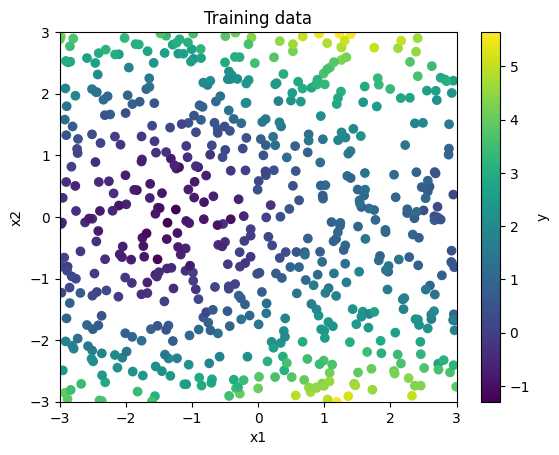

In [3]:
plt.scatter(X_tra[:, 0], X_tra[:, 1], c=Y_tra.ravel())
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Training data")
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.colorbar(label="y")
plt.show()


In [4]:
class RKS:
    def __init__(self, h=256, sigma=1, ridge=1e-3):
        rng = np.random.default_rng(67)
        self.w = rng.normal(size=(h, X_tra.shape[1])) / sigma
        self.b = rng.uniform(0, 2 * np.pi, size=h)
        self.h = h
        self.lin = Ridge(alpha=ridge)

    def features(self, X):
        z = X @ self.w.T + self.b
        return np.concatenate([np.sin(z), np.cos(z)], axis=1) / np.sqrt(self.h)

    def fit(self, X, Y):
        self.lin.fit(self.features(X), Y)
        return self

    def predict(self, X):
        return self.lin.predict(self.features(X))


In [5]:
sigmas = [0.25, 0.5, 1, 2, 4, 8, 16, 32]
rks_tra_losses = []
rks_val_losses = []

for sigma in sigmas:
    rks = RKS(sigma=sigma).fit(X_tra, Y_tra)
    tra_loss = np.mean((rks.predict(X_tra) - Y_tra) ** 2)
    val_loss = np.mean((rks.predict(X_val) - Y_val) ** 2)
    rks_tra_losses.append(tra_loss)
    rks_val_losses.append(val_loss)
    print(f"sigma: {sigma}, train_loss: {tra_loss}, val_loss: {val_loss}")

best_sigma = sigmas[np.argmin(rks_val_losses)]
print("best sigma:", best_sigma)


sigma: 0.25, train_loss: 0.017114437275920207, val_loss: 0.06465205383165097
sigma: 0.5, train_loss: 0.0266077848210996, val_loss: 0.047896442577142435
sigma: 1, train_loss: 0.02979476327471958, val_loss: 0.03938368520264615
sigma: 2, train_loss: 0.03224517814424652, val_loss: 0.036686781928720553
sigma: 4, train_loss: 0.034814562207111946, val_loss: 0.03629287549886897
sigma: 8, train_loss: 0.044412473254221096, val_loss: 0.04744196041868204
sigma: 16, train_loss: 0.18231363348296067, val_loss: 0.1872021267777342


sigma: 32, train_loss: 0.3301936387044792, val_loss: 0.3170018566011188
best sigma: 4


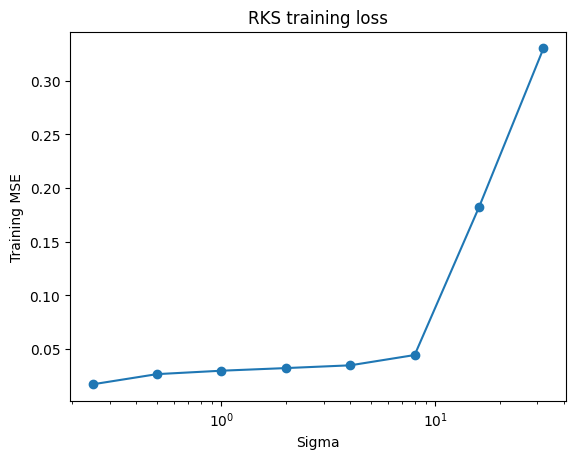

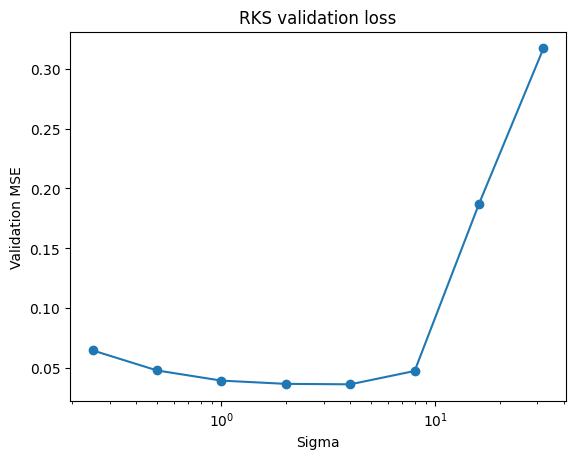

In [6]:
plt.plot(sigmas, rks_tra_losses, marker="o")
plt.xscale("log")
plt.xlabel("Sigma")
plt.ylabel("Training MSE")
plt.title("RKS training loss")
plt.show()

plt.plot(sigmas, rks_val_losses, marker="o")
plt.xscale("log")
plt.xlabel("Sigma")
plt.ylabel("Validation MSE")
plt.title("RKS validation loss")
plt.show()


In [7]:
bs = 128
lr = 1e-3
epochs = 1000
patience = 100
widths = [16, 32, 64, 128, 256, 512]
los = nn.MSELoss()

val_x = torch.tensor(X_val, dtype=torch.float32)
val_y = torch.tensor(Y_val, dtype=torch.float32)
tra_x = torch.tensor(X_tra, dtype=torch.float32)
tra_y = torch.tensor(Y_tra, dtype=torch.float32)

@torch.no_grad()
def eval(model, x, y):
    model.eval()
    return los(model(x), y).item()

def fit(width, n_epochs):
    torch.manual_seed(67)
    model = nn.Sequential(
        nn.Linear(X_tra.shape[1], width),
        nn.ReLU(),
        nn.Linear(width, 1)
    )
    tra_ld = DataLoader(
        TensorDataset(tra_x, tra_y), batch_size=bs, shuffle=True
    )
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_val_loss = float("inf")
    best_model = None
    best_epo = 0
    wait = 0

    for epo in range(n_epochs):
        model.train()
        for x, y in tra_ld:
            opt.zero_grad()
            loss = los(model(x), y)
            loss.backward()
            opt.step()
        val_loss = eval(model, val_x, val_y)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model = copy.deepcopy(model.state_dict())
            best_epo = epo + 1
            wait = 0
        else:
            wait += 1
        if wait >= patience:
            break

    model.load_state_dict(best_model)
    return model, eval(model, tra_x, tra_y), best_val_loss, best_epo


In [8]:
mlp_tra_losses = []
mlp_val_losses = []
mlp_epochs = []

for width in widths:
    model, tra_loss, val_loss, best_epo = fit(width, epochs)
    mlp_tra_losses.append(tra_loss)
    mlp_val_losses.append(val_loss)
    mlp_epochs.append(best_epo)
    print(f"width: {width}, train_loss: {tra_loss}, val_loss: {val_loss}, epoch: {best_epo}")

best_idx = np.argmin(mlp_val_losses)
best_width = widths[best_idx]
best_epochs = mlp_epochs[best_idx]
print("best width:", best_width)


width: 16, train_loss: 0.038735680282115936, val_loss: 0.0472286231815815, epoch: 999


width: 32, train_loss: 0.03262505680322647, val_loss: 0.040420494973659515, epoch: 1000


width: 64, train_loss: 0.03214895352721214, val_loss: 0.0395905077457428, epoch: 752


width: 128, train_loss: 0.030283184722065926, val_loss: 0.03816639259457588, epoch: 847


width: 256, train_loss: 0.030097071081399918, val_loss: 0.03819375857710838, epoch: 553


width: 512, train_loss: 0.030261898413300514, val_loss: 0.03814612701535225, epoch: 346
best width: 512


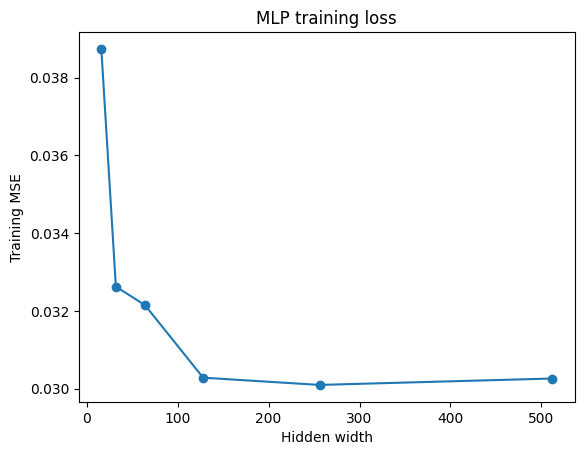

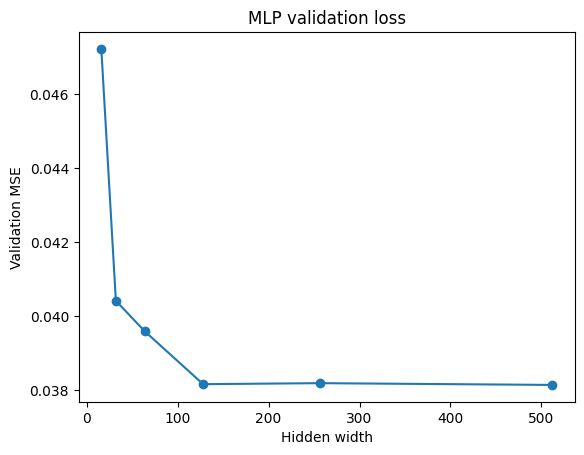

In [9]:
plt.plot(widths, mlp_tra_losses, marker="o")
plt.xlabel("Hidden width")
plt.ylabel("Training MSE")
plt.title("MLP training loss")
plt.show()

plt.plot(widths, mlp_val_losses, marker="o")
plt.xlabel("Hidden width")
plt.ylabel("Validation MSE")
plt.title("MLP validation loss")
plt.show()


In [10]:
rks = RKS(sigma=best_sigma).fit(X_tra, Y_tra)
model, tra_loss, val_loss, best_epo = fit(best_width, best_epochs)

results = pd.DataFrame({
    "model": ["RKS", "MLP"],
    "train mse": [np.mean((rks.predict(X_tra) - Y_tra) ** 2), tra_loss],
    "val mse": [np.mean((rks.predict(X_val) - Y_val) ** 2), val_loss]
})
display(results)


,model,train mse,val mse
0,RKS,0.034815,0.036293
1,MLP,0.030262,0.038146


In [11]:
rks_pred = rks.predict(X_tes).ravel()
model.eval()
with torch.no_grad():
    mlp_pred = model(torch.tensor(X_tes, dtype=torch.float32)).numpy().ravel()

pd.DataFrame({"y": rks_pred}).to_csv("rks_test_predictions.csv", index=False)
pd.DataFrame({"y": mlp_pred}).to_csv("mlp_test_predictions.csv", index=False)


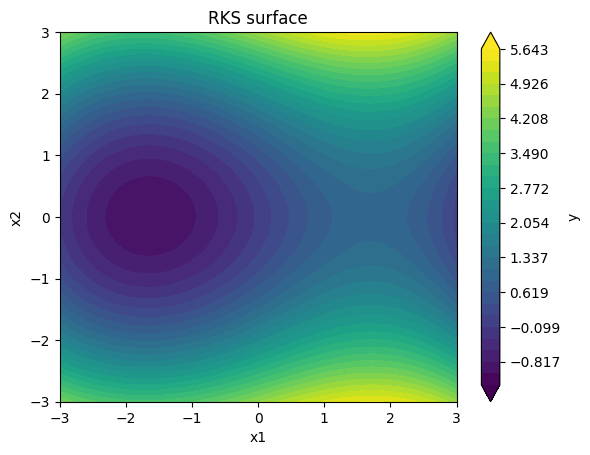

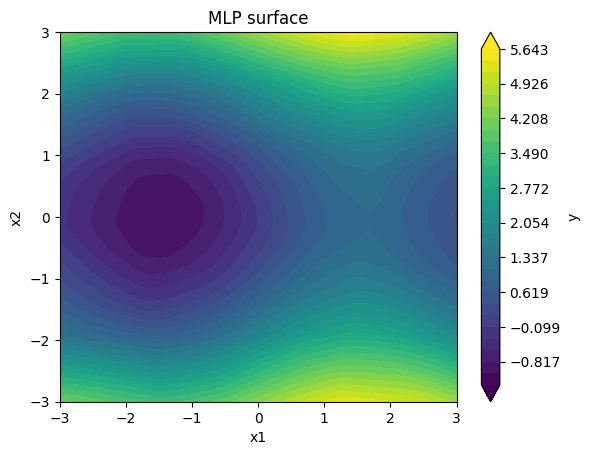

In [12]:
axis = np.linspace(-3, 3, 100)
x1, x2 = np.meshgrid(axis, axis)
grid = np.column_stack([x1.ravel(), x2.ravel()]).astype(np.float32)

rks_grid = rks.predict(grid).reshape(x1.shape)
with torch.no_grad():
    mlp_grid = model(torch.tensor(grid)).numpy().reshape(x1.shape)

levels = np.linspace(Y_tra.min(), Y_tra.max(), 30)
for z, title in [(rks_grid, "RKS surface"), (mlp_grid, "MLP surface")]:
    plt.contourf(x1, x2, z, levels=levels, extend="both")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.colorbar(label="y")
    plt.show()



Hyperparameter choices: 
The best choice of sigma for RKD was 4. This gave 256 pairs of random features and had a ridge strength of 0.001. It reached a validation MSE of 0.03629.

The best MLP hidden width was 512. It reached a validation MSE of 0.03815. It was slightly overfit, as the training MSE was lower than the validation MSE. 

We can see that the resulting surfaces from both the MLP and the RKS had a minima in the (1.5, 0) area, with a slightly higher gradient along the x1 direction than along the x2 direction. The true surface is smooth, and the RKS is able to learn a smooth approximation to the surfae, because it is able to use smooth differentiable features. The MLP is slightly more choppy in its level sets, because it is constructed from piecewise functions like ReLUs. The smoother fit from RKS was actually empirically better in terms of validation MSE. 


